**Нейросеть для предсказания калорийности блюд**

**Цель**
Получить DL-модель, способную оценить калорийность блюда.

**Целевая метрика**
Модель будет считаться готовой к интеграции в продукт при точности оценки MAE < 50 (MAE — Mean Absolute Error) на тестовой выборке.

In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
import zipfile
import os

archive_path = "/content/drive/MyDrive/nutrition.zip"  # <-- укажи свой точный путь
extract_to = "/content"

with zipfile.ZipFile(archive_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to)

print("Распаковано. Файлы:")
!ls -R /content

Выходные данные были обрезаны до нескольких последних строк (5000).
rgb.png

/content/data/images/dish_1562945879:
rgb.png

/content/data/images/dish_1562945900:
rgb.png

/content/data/images/dish_1562946006:
rgb.png

/content/data/images/dish_1562946075:
rgb.png

/content/data/images/dish_1562946106:
rgb.png

/content/data/images/dish_1562947020:
rgb.png

/content/data/images/dish_1562947376:
rgb.png

/content/data/images/dish_1562947409:
rgb.png

/content/data/images/dish_1562947436:
rgb.png

/content/data/images/dish_1562947469:
rgb.png

/content/data/images/dish_1562947503:
rgb.png

/content/data/images/dish_1562947598:
rgb.png

/content/data/images/dish_1562947885:
rgb.png

/content/data/images/dish_1562949162:
rgb.png

/content/data/images/dish_1562949205:
rgb.png

/content/data/images/dish_1562949242:
rgb.png

/content/data/images/dish_1562949467:
rgb.png

/content/data/images/dish_1562949494:
rgb.png

/content/data/images/dish_1562949541:
rgb.png

/content/data/images/dish_1562

In [4]:
!ls /content
!ls /content/data


data  drive  sample_data
dish.csv  images  ingredients.csv


In [5]:
!pip install --quiet transformers timm albumentations torchmetrics pandas numpy



**Этап 1. Проведите исследовательский анализ (EDA)**

In [6]:
import os
import numpy as np
import pandas as pd
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2
import torch
import torch.nn as nn
from torch.optim import AdamW
from torch.utils.data import DataLoader
import torchmetrics
import timm
from transformers import AutoModel, AutoTokenizer
from functools import partial
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

dish.csv: (3262, 5)
ingredients.csv: (555, 2)


,dish_id,total_calories,total_mass,ingredients,split
0,dish_1561662216,300.794281,193.0,ingr_0000000508;ingr_0000000122;ingr_000000002...,test
1,dish_1561662054,419.438782,292.0,ingr_0000000312;ingr_0000000026;ingr_000000002...,train
2,dish_1562008979,382.936646,290.0,ingr_0000000448;ingr_0000000520;ingr_000000046...,test
3,dish_1560455030,20.590000,103.0,ingr_0000000471;ingr_0000000031;ingr_0000000347,train
4,dish_1558372433,74.360001,143.0,ingr_0000000453,train
5,dish_1565640549,45.482903,139.0,ingr_0000000032;ingr_0000000523;ingr_000000016...,train
6,dish_1563207364,309.269989,271.0,ingr_0000000008;ingr_0000000192;ingr_000000044...,train
7,dish_1561575474,120.058434,183.0,ingr_0000000291;ingr_0000000335;ingr_000000043...,train
8,dish_1563216717,246.007996,332.0,ingr_0000000122;ingr_0000000021;ingr_000000047...,train
9,dish_1565972591,195.199997,122.0,ingr_0000000510,train


,id,ingr
0,1,cottage cheese
1,2,strawberries
2,3,garden salad
3,4,bacon
4,5,potatoes
5,6,caesar salad
6,7,cauliflower
7,8,scrambled eggs
8,9,wild rice
9,10,steak



Пропуски в dish.csv:
 dish_id           0
total_calories    0
total_mass        0
ingredients       0
split             0
dtype: int64

Пропуски в ingredients.csv:
 id      0
ingr    0
dtype: int64

Дубликаты в ingredients.csv по id: 0

Разбивка по split:
 split
train    2755
test      507
Name: count, dtype: int64


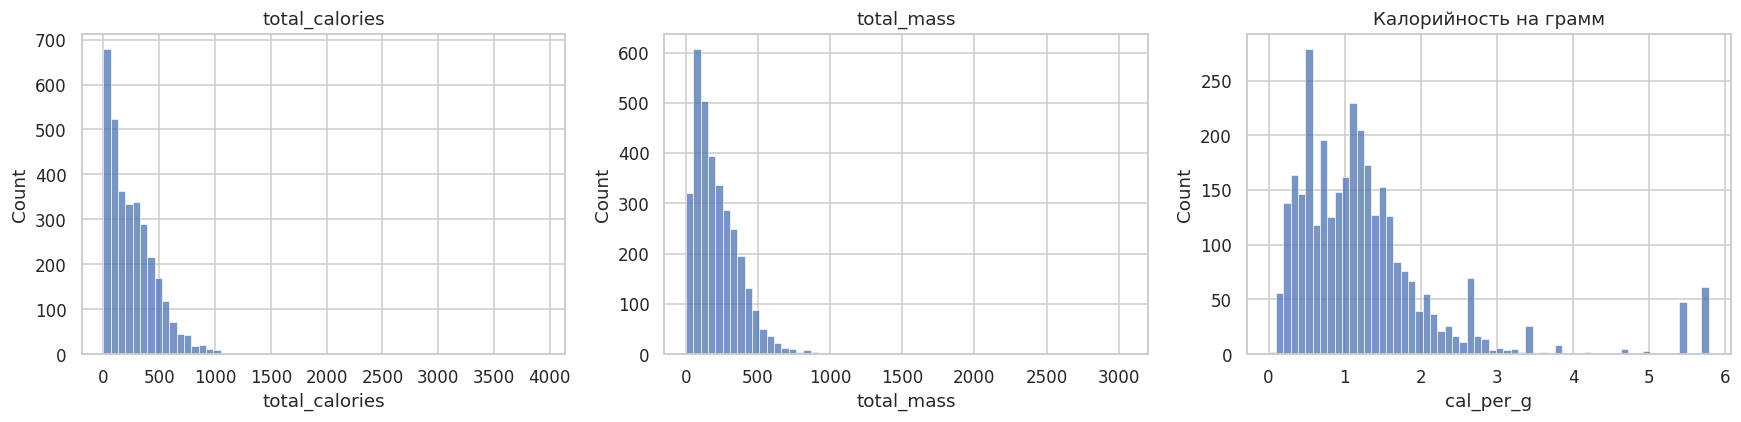

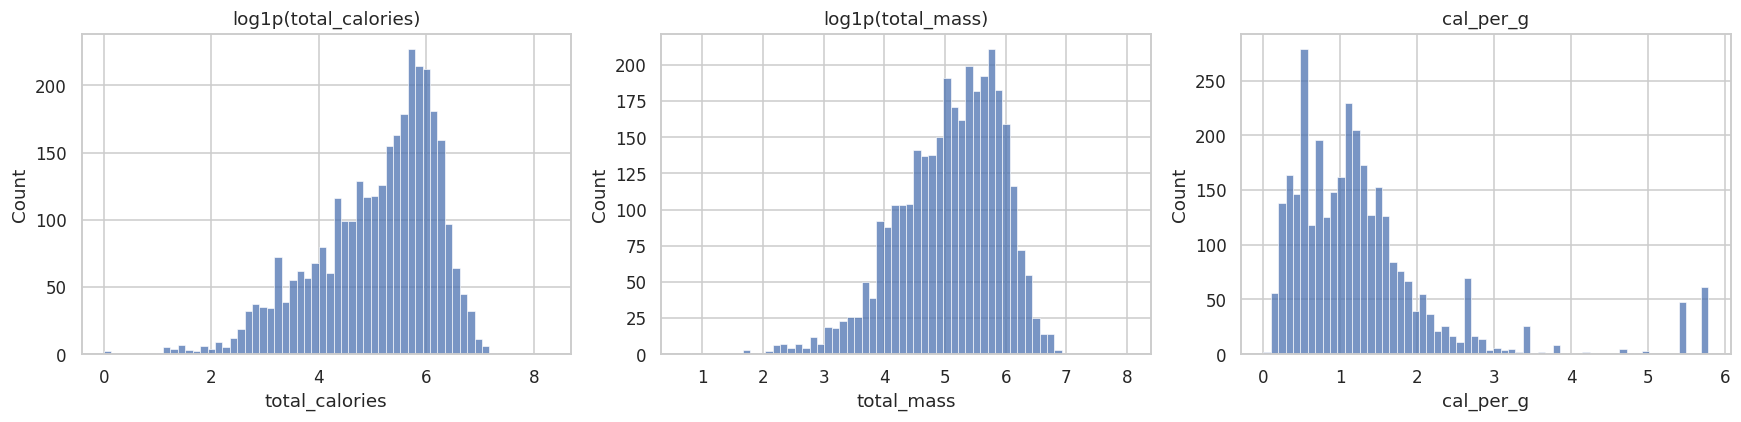

       total_calories   total_mass    cal_per_g
count     3262.000000  3262.000000  3262.000000
mean       255.012738   214.980074     1.303877
std        219.637570   161.497428     1.067080
min          0.000000     1.000000     0.000000
25%         80.114996    92.000000     0.604278
50%        209.110062   177.000000     1.101661
75%        375.122963   305.000000     1.556691
max       3943.325195  3051.000000     5.781000

Квантили калорий: {0.01: 6.3659, 0.5: 209.110062, 0.99: 918.53512193}
Квантили массы:   {0.01: 14.0, 0.5: 177.0, 0.99: 702.3399999999992}

Подозрительных строк: 6
Примеры id из ingredients.csv: [1, 2, 3]

Пример замены ID -> названия:
  ingr_0000000508;ingr_0000000122;ingr_0000000026;ingr_0000000524;ingr_0000000094;ingr_0000000023;ingr_0000000189;ingr_0000000054;ingr_0000000029;ingr_0000000328;ingr_0000000291;ingr_0000000520;ingr_0000000161;ingr_0000000462;ingr_0000000525;ingr_0000000312;ingr_0000000513
  => soy sauce, garlic, white rice, parsley, onions, brown

/tmp/ipykernel_810/2224994344.py:116: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top10, y='name', x='count', palette='viridis')


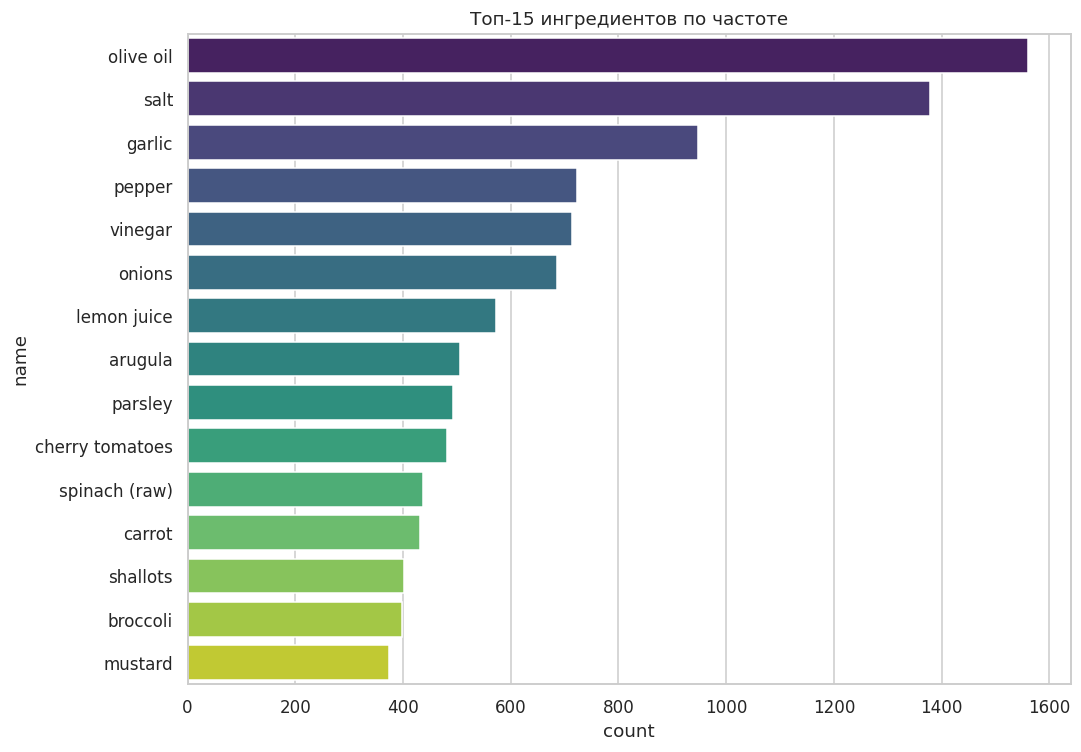


Число ингредиентов в блюде:
count    3262.000000
mean        7.313305
std         6.943276
min         1.000000
25%         1.000000
50%         4.000000
75%        12.000000
max        34.000000
Name: n_ingredients, dtype: float64


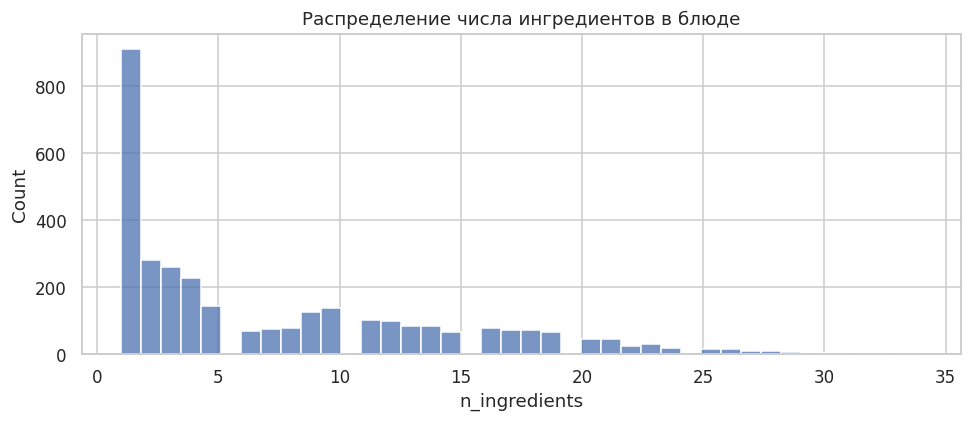


Ингредиенты самых калорийных блюд (по плотности):
             id              name  n_dishes   mean_cal  mean_cal_per_g
ingr_0000000297         pepperoni         2 485.154999        4.252457
ingr_0000000077           almonds       173 394.219739        3.152268
ingr_0000000287             toast         1 263.003998        3.131000
ingr_0000000257          brownies        15 696.374147        3.018615
ingr_0000000208   ice cream cones         2 101.068504        2.988455
ingr_0000000067             syrup         1 493.589081        2.836719
ingr_0000000004             bacon       190 326.881123        2.676816
ingr_0000000019             bread         1 122.084000        2.654000
ingr_0000000455           cookies         9 493.730982        2.615533
ingr_0000000243 mozzarella cheese         1 384.175995        2.462667
ingr_0000000039           sausage        95 500.890150        2.445156
ingr_0000000200        buttermilk         8 747.018089        2.223511
ingr_0000000221     vegeta

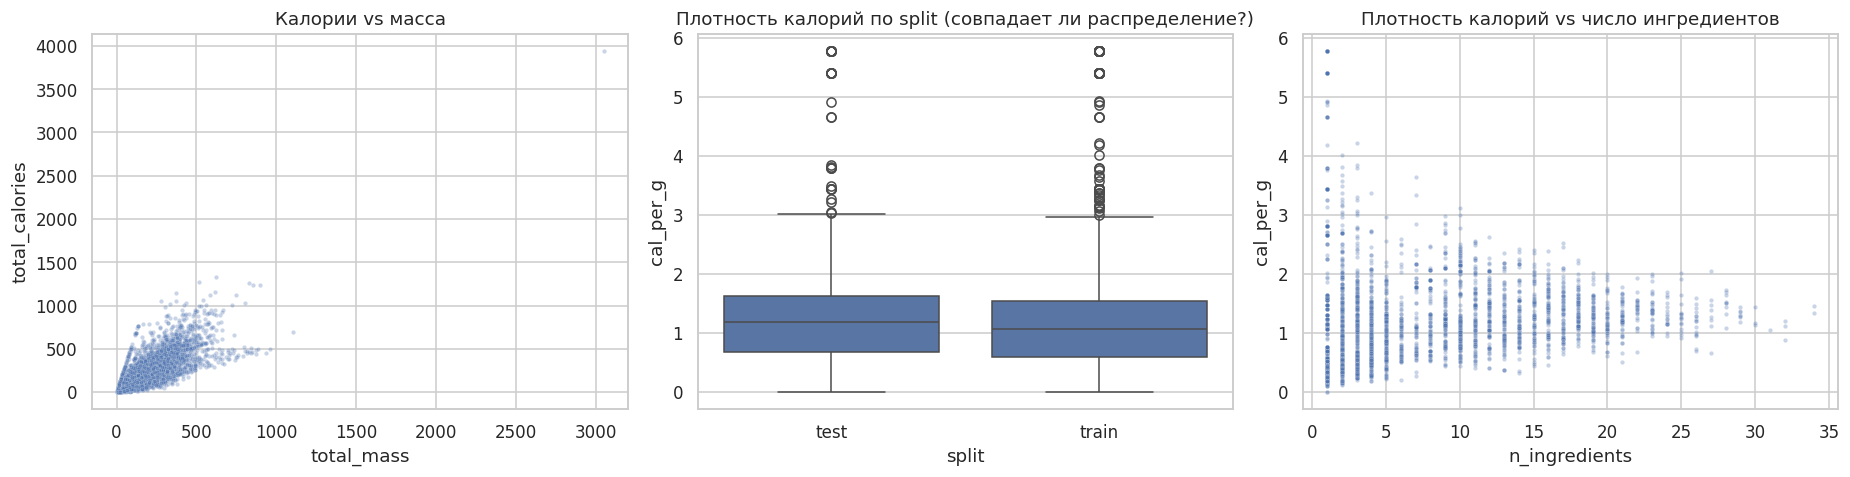


Корреляции с total_calories:
total_calories    1.000000
total_mass        0.759676
n_ingredients     0.476230
cal_per_g         0.320458
Name: total_calories, dtype: float64

train: 2755 блюд, mean cal_per_g = 1.280
test:  507 блюд, mean cal_per_g = 1.436


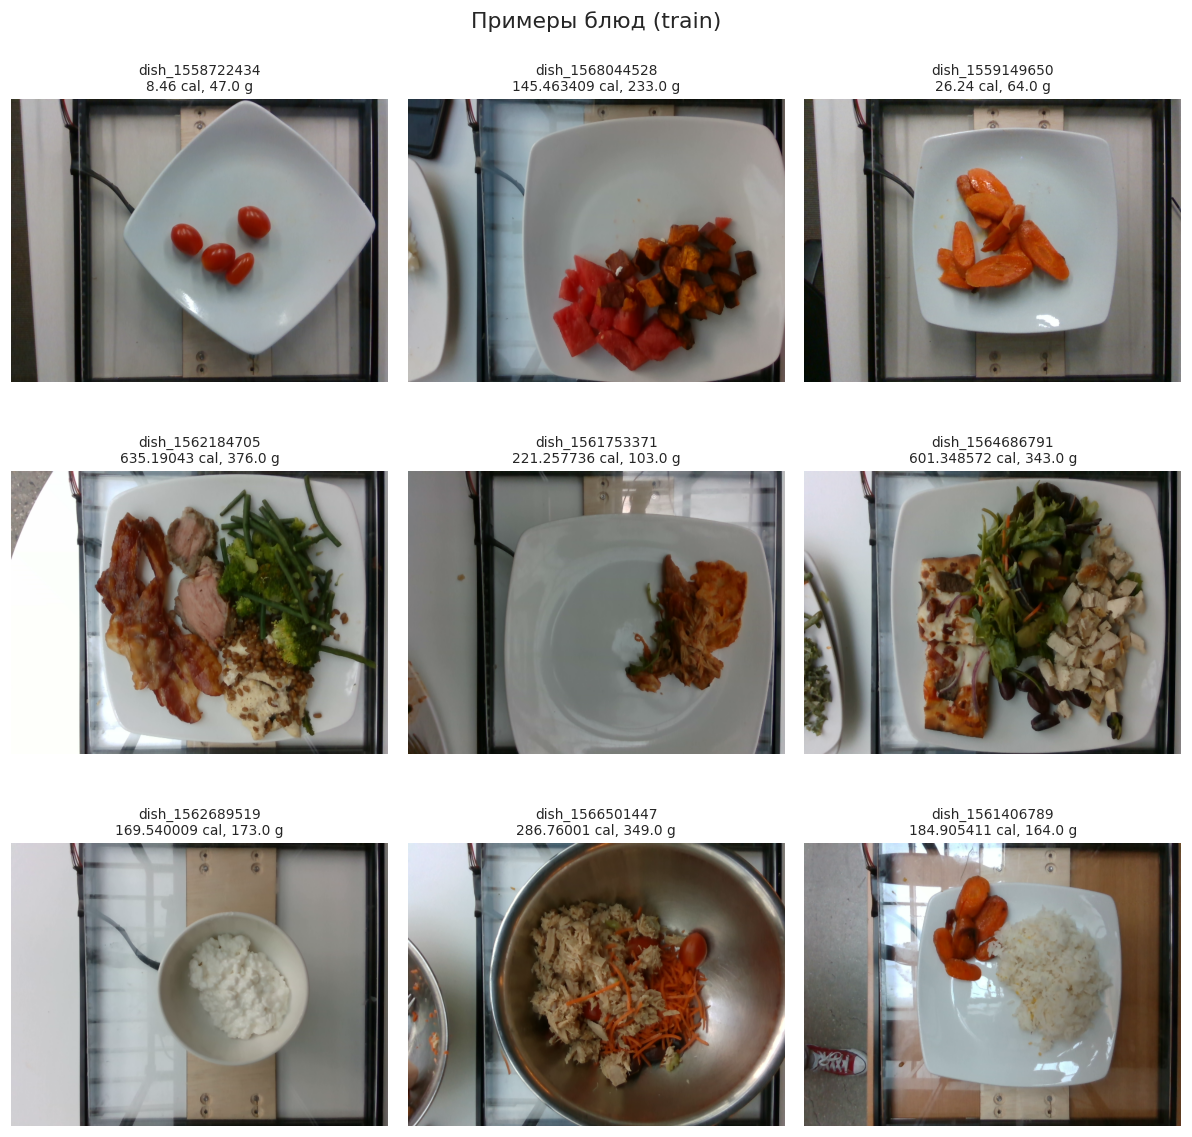

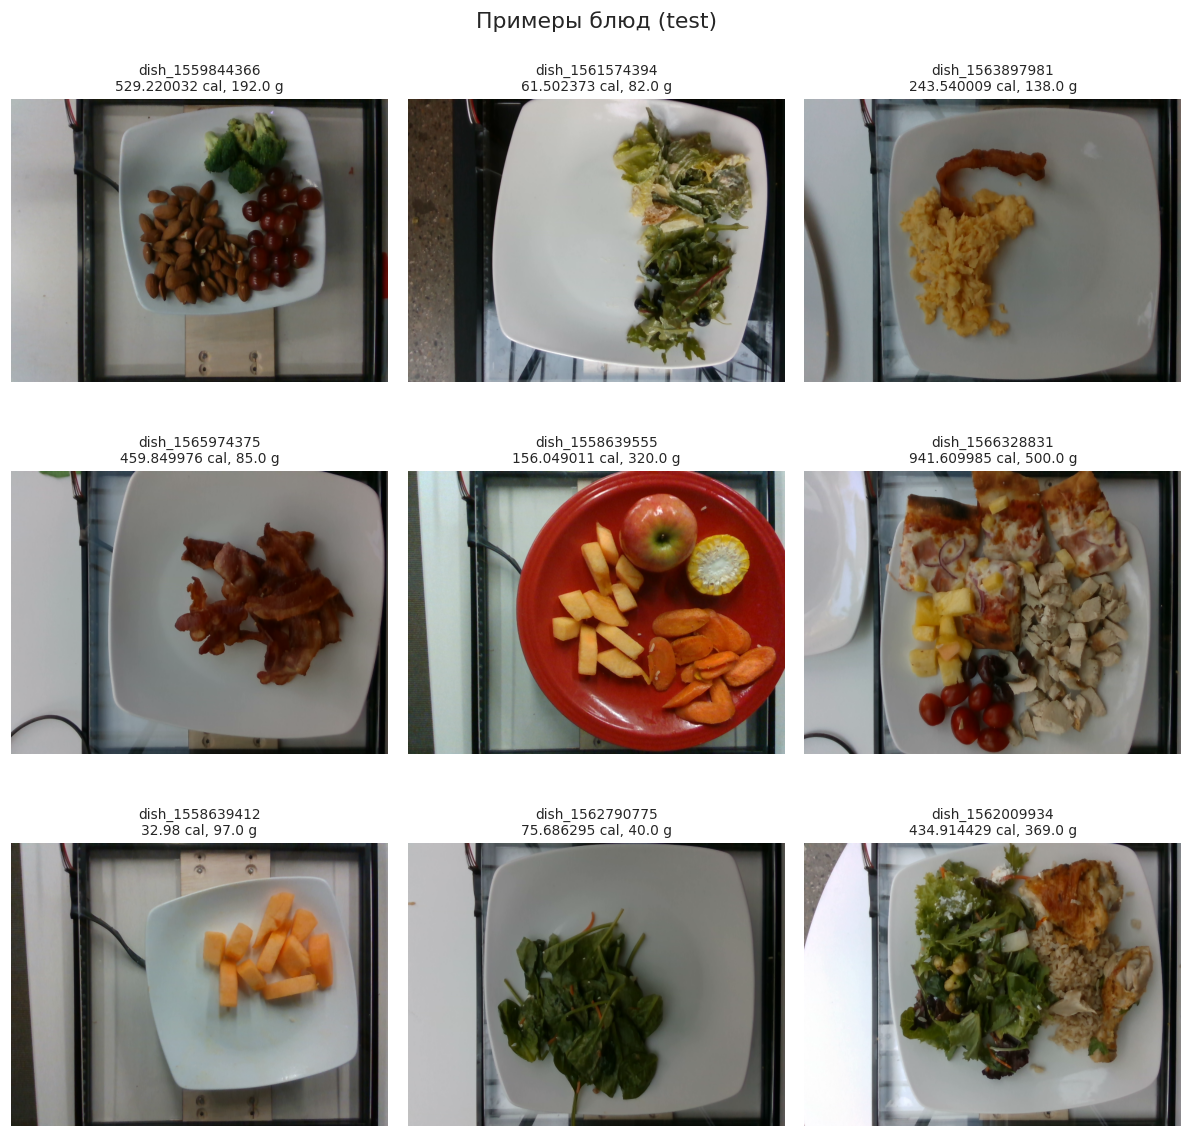


Блюд без фото: 0
Папок без блюда в dish.csv: 228
Распределение размеров изображений (выборка 200): [((640, 480), 200)]


In [7]:
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110

# ------------------------------------------------------------
# 1. Загрузка и первый осмотр
# ------------------------------------------------------------
dish = pd.read_csv('data/dish.csv')
ingr = pd.read_csv('data/ingredients.csv')

print('dish.csv:', dish.shape)
print('ingredients.csv:', ingr.shape)
display(dish.head(10))
display(ingr.head(10))

print('\nПропуски в dish.csv:\n', dish.isna().sum())
print('\nПропуски в ingredients.csv:\n', ingr.isna().sum())
print('\nДубликаты в ingredients.csv по id:', ingr['id'].duplicated().sum())

# Разбивка train/test
print('\nРазбивка по split:\n', dish['split'].value_counts())

# ------------------------------------------------------------
# 2. Целевая переменная и масса: распределения и выбросы
# ------------------------------------------------------------
dish['cal_per_g'] = dish['total_calories'] / dish['total_mass']

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(dish['total_calories'], bins=60, ax=axes[0])
axes[0].set_title('total_calories')
sns.histplot(dish['total_mass'], bins=60, ax=axes[1])
axes[1].set_title('total_mass')
sns.histplot(dish['cal_per_g'], bins=60, ax=axes[2])
axes[2].set_title('Калорийность на грамм')
plt.tight_layout()
plt.savefig('eda_01_targets.png')
plt.show()

# Распределения могут быть скошены — смотрим в лог-шкале
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(np.log1p(dish['total_calories']), bins=60, ax=axes[0])
axes[0].set_title('log1p(total_calories)')
sns.histplot(np.log1p(dish['total_mass']), bins=60, ax=axes[1])
axes[1].set_title('log1p(total_mass)')
sns.histplot(dish['cal_per_g'], bins=60, ax=axes[2])
axes[2].set_title('cal_per_g')
plt.tight_layout()
plt.savefig('eda_02_targets_log.png')
plt.show()

print(dish[['total_calories', 'total_mass', 'cal_per_g']].describe())
print('\nКвантили калорий:', dish['total_calories'].quantile([0.01, 0.5, 0.99]).to_dict())
print('Квантили массы:  ', dish['total_mass'].quantile([0.01, 0.5, 0.99]).to_dict())

# Выбросы: нулевая/аномальная калорийность или масса
weird = dish[(dish['total_calories'] <= 0) |
             (dish['total_mass'] <= 0) |
             (dish['cal_per_g'] > dish['cal_per_g'].quantile(0.999)) |
             (dish['cal_per_g'] < dish['cal_per_g'].quantile(0.001))]
print(f'\nПодозрительных строк: {len(weird)}')
weird[['dish_id', 'total_calories', 'total_mass', 'cal_per_g']].head(10)

# ------------------------------------------------------------
# 3. Объединение таблиц: ID -> названия продуктов
# ------------------------------------------------------------
# Проверяем формат id в ingredients.csv (может быть как '122', так и 'ingr_0000000122')
print('Примеры id из ingredients.csv:', ingr['id'].head(3).tolist())

# Строим словарь в ОБОИХ форматах — это страховка от несовпадения форматов:
# имена заменятся и по 'ingr_0000000122', и по '122'
def norm_id(i):
    s = str(i)
    return s if s.startswith('ingr_') else 'ingr_' + s.zfill(10)

id2name_full = {norm_id(i): name for i, name in zip(ingr['id'], ingr['ingr'])}
id2name_raw  = dict(zip(ingr['id'], ingr['ingr']))

def ids_to_names(s):
    parts = s.split(';')
    names = [id2name_full.get(p, id2name_raw.get(p, f'UNKNOWN({p})')) for p in parts]
    return ', '.join(names)

dish['ingredients_names'] = dish['ingredients'].apply(ids_to_names)

# Демонстрация результата замены
print('\nПример замены ID -> названия:')
for _, row in dish.head(5).iterrows():
    print(f'  {row["ingredients"]}\n  => {row["ingredients_names"]}\n')

# Проверка: все ли ID нашлись в справочнике
known = set(id2name_full) | set(id2name_raw)
unknown_ids = Counter()
for s in dish['ingredients']:
    for p in s.split(';'):
        if p not in known:
            unknown_ids[p] += 1
print(f'Неизвестных ID (нет в ingredients.csv): {len(unknown_ids)}')
if unknown_ids:
    print(unknown_ids.most_common(10))

# ------------------------------------------------------------
# 4. Анализ ингредиентов
# ------------------------------------------------------------
# Частоты ингредиентов
cnt = Counter()
for s in dish['ingredients']:
    cnt.update(s.split(';'))

freq = pd.DataFrame(cnt.most_common(25), columns=['id', 'count'])
freq['name'] = freq['id'].map(id2name_full)
freq['share_of_dishes'] = freq['count'] / len(dish)
print('\nТоп-25 самых частых ингредиентов:')
print(freq.to_string(index=False))

plt.figure(figsize=(10, 7))
top10 = freq.head(15)
sns.barplot(data=top10, y='name', x='count', palette='viridis')
plt.title('Топ-15 ингредиентов по частоте')
plt.tight_layout()
plt.savefig('eda_03_top_ingredients.png')
plt.show()

# Сколько ингредиентов в блюде
dish['ingr_list'] = dish['ingredients'].str.split(';')
dish['n_ingredients'] = dish['ingr_list'].apply(len)
print('\nЧисло ингредиентов в блюде:')
print(dish['n_ingredients'].describe())

plt.figure(figsize=(9, 4))
sns.histplot(dish['n_ingredients'], bins=40)
plt.title('Распределение числа ингредиентов в блюде')
plt.tight_layout()
plt.savefig('eda_04_n_ingredients.png')
plt.show()

# Средняя калорийность блюд по каждому ингредиенту
# (какие продукты тянут калории вверх/вниз)
stat_rows = []
for ing, c in cnt.items():
    mask = dish['ingr_list'].apply(lambda l: ing in l)
    stat_rows.append({
        'id': ing,
        'name': id2name_full.get(ing, ing),
        'n_dishes': int(mask.sum()),
        'mean_cal': dish.loc[mask, 'total_calories'].mean(),
        'mean_cal_per_g': dish.loc[mask, 'cal_per_g'].mean(),
    })
ingr_stat = pd.DataFrame(stat_rows).sort_values('mean_cal_per_g', ascending=False)

print('\nИнгредиенты самых калорийных блюд (по плотности):')
print(ingr_stat.head(15).to_string(index=False))
print('\nИнгредиенты самых «лёгких» блюд (по плотности):')
print(ingr_stat.tail(15).to_string(index=False))

# ------------------------------------------------------------
# 5. Взаимосвязи признаков с целевой переменной
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.scatterplot(data=dish, x='total_mass', y='total_calories',
                s=8, alpha=0.3, ax=axes[0])
axes[0].set_title('Калории vs масса')
sns.boxplot(data=dish, x='split', y='cal_per_g', ax=axes[1])
axes[1].set_title('Плотность калорий по split (совпадает ли распределение?)')
sns.scatterplot(data=dish, x='n_ingredients', y='cal_per_g',
                s=8, alpha=0.3, ax=axes[2])
axes[2].set_title('Плотность калорий vs число ингредиентов')
plt.tight_layout()
plt.savefig('eda_05_relations.png')
plt.show()

print('\nКорреляции с total_calories:')
print(dish[['total_calories', 'total_mass', 'n_ingredients', 'cal_per_g']].corr()['total_calories'])

# Train и test похожи?
train = dish[dish['split'] == 'train']
test = dish[dish['split'] == 'test']
print(f'\ntrain: {len(train)} блюд, mean cal_per_g = {train["cal_per_g"].mean():.3f}')
print(f'test:  {len(test)} блюд, mean cal_per_g = {test["cal_per_g"].mean():.3f}')

# ------------------------------------------------------------
# 6. Визуализация фотографий блюд
# ------------------------------------------------------------
IMG_ROOT = 'data/images'

def show_photos(df, n=9, title='Примеры блюд'):
    sample = df.sample(n=min(n, len(df)), random_state=42)
    fig, axes = plt.subplots(3, 3, figsize=(11, 11))
    found = 0
    for ax, (_, row) in zip(axes.ravel(), sample.iterrows()):
        path = os.path.join(IMG_ROOT, str(row['dish_id']), 'rgb.png')
        if os.path.exists(path):
            ax.imshow(Image.open(path))
            ax.set_title(f"{row['dish_id']}\n{row['total_calories']} cal, "
                         f"{row['total_mass']} g", fontsize=9)
            found += 1
        else:
            ax.set_title('нет файла')
        ax.axis('off')
    plt.suptitle(title)
    plt.tight_layout()
    plt.savefig('eda_06_samples.png')
    plt.show()
    return found

# примеры из train и из test
show_photos(train, title='Примеры блюд (train)')
show_photos(test, title='Примеры блюд (test)')

# Проверяем целостность картинок: все ли dish_id имеют rgb.png
ids_all = set(dish['dish_id'].astype(str))
ids_img = set(os.listdir(IMG_ROOT))
print(f'\nБлюд без фото: {len(ids_all - ids_img)}')
print(f'Папок без блюда в dish.csv: {len(ids_img - ids_all)}')

# Размеры картинок на небольшой выборке
sizes = Counter()
for did in list(ids_img)[:200]:
    p = os.path.join(IMG_ROOT, did, 'rgb.png')
    if os.path.exists(p):
        with Image.open(p) as im:
            sizes[im.size] += 1
print('Распределение размеров изображений (выборка 200):', sizes.most_common(5))


**Этап 1. Выводы**
Датасет содержит 3262 блюда и 555 уникальных ингредиентов. Соотношение train/test = 2755/507.
Пропусков нет, ID в справочнике все найдены, замена технических идентификаторов на названия продуктов выполнена.

Есть фото пустой тарелки - у него нулевая калорийность.

Целевая переменная total_calories скошена вправо. Целевая переменная коррелирует с массой порции, что логично, но коррелирует сильнее, чем с плотностью, что значит надо сначала предсказывать калорийность исходя из состава, а потом уже учитывать массу блюда.
Калорийные продукты (bacon, almonds, pepperoni) и лёгкие (watermelon, melon) дают чёткое разделение по средней плотности.

Скорее всего нужна мультимодальная модель, которая будет учитывать количество ингредиентов (текст), визуальное наполение (изображение), само названия ингридиентов (текст).

Для изображений можно попробовать RandomResizedCrop, горизонтальный флип, ColorJitter (разное освещение/ракурсы).
Метрики: MAE (основная, интерпретируемая в калориях)

**Этап 2. Реализуйте пайплайн обучения**

In [8]:
!cp /content/drive/MyDrive/{dataset.py,utils.py,config.yaml} /content/

import os
os.chdir('/content')
print(os.getcwd())
print(os.path.exists('data/dish.csv'), os.path.exists('data/images'))


/content
True True


**Этап 3. Обучение модели**

In [9]:
!pip install timm transformers albumentations torchmetrics -q

from utils import train
metrics = train("config.yaml")


Device: cuda


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

... (2 outputs left out)

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

[эпоха 01] train loss=0.4094 MAE=73.8 RMSE=116.7 | val loss=0.2927 MAE=56.7 RMSE=94.4
  -> сохранён лучший чекпоинт (val MAE=56.7 кал)
[эпоха 02] train loss=0.2744 MAE=56.8 RMSE=99.0 | val loss=0.1818 MAE=40.8 RMSE=69.0
  -> сохранён лучший чекпоинт (val MAE=40.8 кал)
[эпоха 03] train loss=0.2472 MAE=50.0 RMSE=80.6 | val loss=0.1713 MAE=40.7 RMSE=67.6
  -> сохранён лучший чекпоинт (val MAE=40.7 кал)
[эпоха 04] train loss=0.2287 MAE=46.0 RMSE=77.5 | val loss=0.1642 MAE=38.7 RMSE=65.9
  -> сохранён лучший чекпоинт (val MAE=38.7 кал)
[эпоха 05] train loss=0.2152 MAE=44.6 RMSE=75.0 | val loss=0.1914 MAE=43.0 RMSE=68.6
[эпоха 06] train loss=0.2122 MAE=43.5 RMSE=73.6 | val loss=0.1914 MAE=44.6 RMSE=76.2
[эпоха 07] train loss=0.1992 MAE=40.5 RMSE=67.0 | val loss=0.2482 MAE=52.7 RMSE=84.5
[эпоха 08] train loss=0.1895 MAE=38.3 RMSE=64.8 | val loss=0.1733 MAE=37.3 RMSE=64.9
  -> сохранён лучший чекпоинт (val MAE=37.3 кал)
[эпоха 09] train loss=0.1737 MAE=36.6 RMSE=63.0 | val loss=0.1542 MAE=35.4

**Этап 4. Валидация качества**


In [10]:

import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import DataLoader
from transformers import AutoTokenizer
import os

from utils import CalorieModel, load_cfg, set_seed, make_collate
from dataset import FoodCaloriesDataset, build_transforms

set_seed(42)
cfg = load_cfg("config.yaml")
device = "cuda" if torch.cuda.is_available() else "cpu"

# --- 1. Загружаем чекпоинт и восстанавливаем модель ---
ckpt = torch.load(cfg.get("save_path", "best_model.pt"), map_location=device)
model = CalorieModel(
    text_model_name=cfg.get("text_model", "distilbert-base-uncased"),
    image_model_name=cfg.get("image_model", "resnet18"),
    hidden_dim=cfg.get("hidden_dim", 256),
    dropout=cfg.get("dropout", 0.2)).to(device)
model.load_state_dict(ckpt["model_state"])
model.eval()
print(f"Загружен чекпоинт эпохи {ckpt.get('epoch')}")

# --- 2. Test-датасет ---
dish = pd.read_csv(cfg["dish_csv"])
df_test = dish[dish["split"] == "test"].reset_index(drop=True)

tokenizer = AutoTokenizer.from_pretrained(cfg.get("text_model", "distilbert-base-uncased"))
collate = make_collate(tokenizer, cfg.get("max_len", 64))

test_ds = FoodCaloriesDataset(df_test, cfg["ingredients_csv"], cfg["image_root"],
                              build_transforms(cfg.get("image_size", 224), augment=False))
test_loader = DataLoader(test_ds, batch_size=cfg.get("batch_size", 4), shuffle=False,
                         num_workers=2, collate_fn=collate)

# --- 3. Инференс: предсказываем плотность, возвращаемся к калориям ---
preds_all, targets_all = [], []
with torch.no_grad():
    for batch in test_loader:
        preds = model(batch["input_ids"].to(device),
                      batch["attention_mask"].to(device),
                      batch["images"].to(device))
        preds_cal = preds.cpu() * batch["masses"]      # плотность -> калории
        targets_cal = batch["targets"] * batch["masses"]
        preds_all.append(preds_cal)
        targets_all.append(targets_cal)

preds_all = torch.cat(preds_all).numpy()
targets_all = torch.cat(targets_all).numpy()

# --- 4. Финальная метрика ---
mae = np.abs(preds_all - targets_all).mean()
rmse = np.sqrt(((preds_all - targets_all) ** 2).mean())
mape = (np.abs(preds_all - targets_all) / np.clip(targets_all, 1, None)).mean() * 100

print(f"\n===== ИТОГ НА TEST =====")
print(f"MAE  = {mae:.1f} кал")
print(f"RMSE = {rmse:.1f} кал")
print(f"MAPE = {mape:.1f} %")
print(f"Цель MAE < 50: {'ДОСТИГНУТА' if mae < 50 else 'НЕ достигнута'}")


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Загружен чекпоинт эпохи 10

===== ИТОГ НА TEST =====
MAE  = 39.9 кал
RMSE = 75.1 кал
MAPE = 13.6 %
Цель MAE < 50: ДОСТИГНУТА


In [11]:

if "ingredients_names" not in df_test.columns:
    ingr = pd.read_csv(cfg["ingredients_csv"])
    id2name = dict(zip(ingr["id"].astype(int), ingr["ingr"].astype(str)))

    def ids_to_names(s: str) -> str:
        names = []
        for token in str(s).split(";"):
            try:
                idx = int(token.replace("ingr_", "").lstrip("0") or 0)
                names.append(id2name.get(idx, token))
            except ValueError:
                names.append(token)
        return ", ".join(names)

    df_test["ingredients_names"] = df_test["ingredients"].apply(ids_to_names)


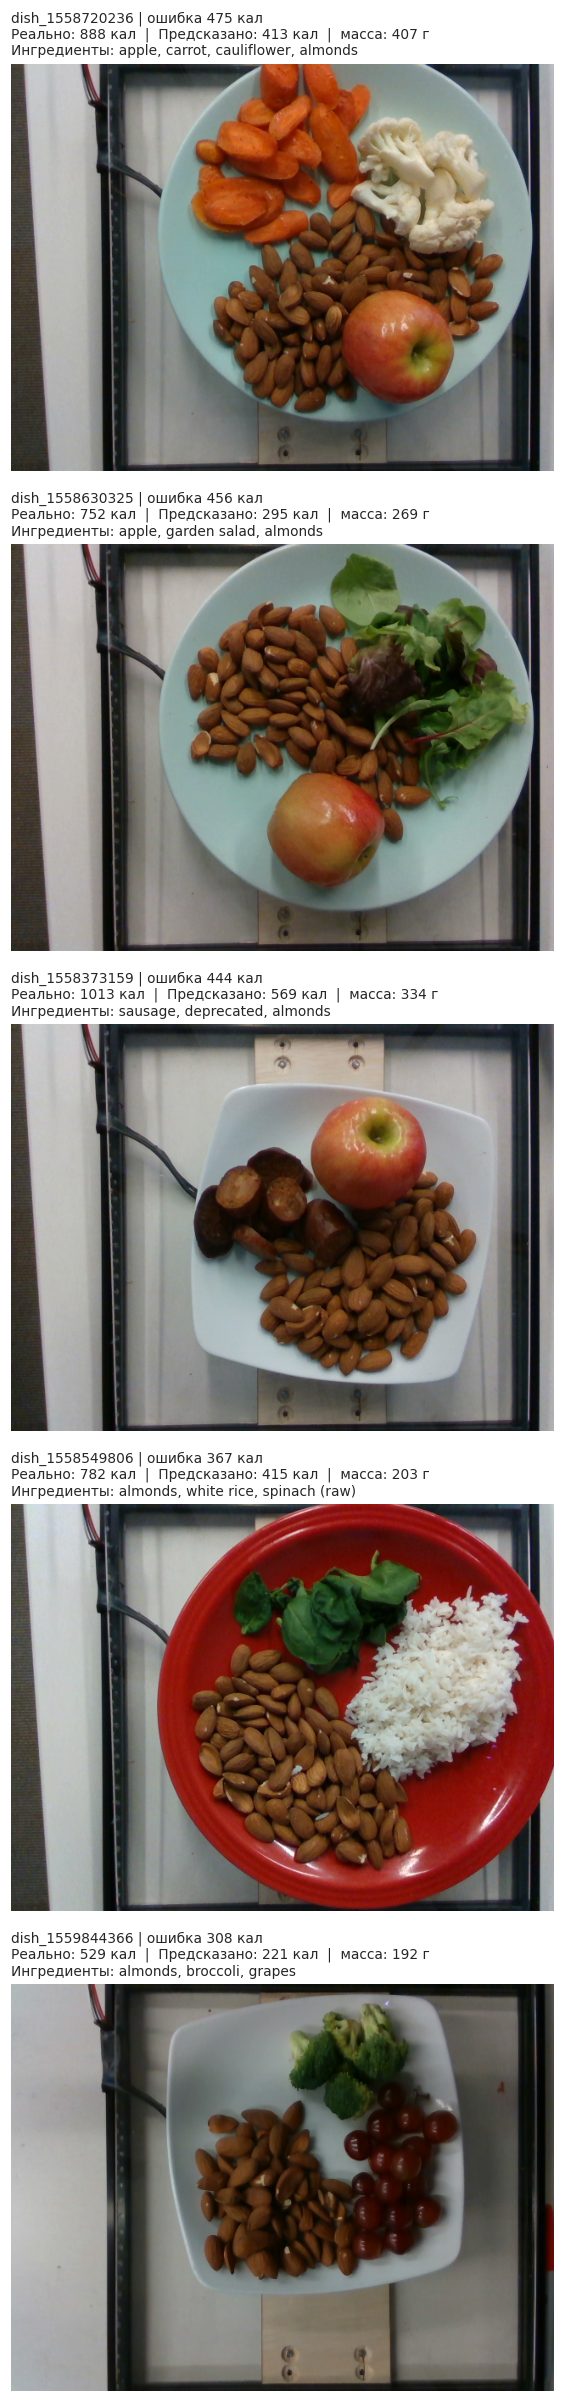

In [12]:
# --- 5. Топ-5 ошибок: фото + ингредиенты + факт/предсказание ---
df_test["pred_cal"] = preds_all
df_test["error"] = np.abs(preds_all - targets_all)
worst = df_test.sort_values("error", ascending=False).head(5)

fig, axes = plt.subplots(5, 1, figsize=(8, 22))
for ax, (_, row) in zip(axes, worst.iterrows()):
    img_path = os.path.join(cfg["image_root"], str(row["dish_id"]), "rgb.png")
    if os.path.exists(img_path):
        ax.imshow(Image.open(img_path))
    ax.axis("off")
    ax.set_title(
        f"{row['dish_id']} | ошибка {row['error']:.0f} кал\n"
        f"Реально: {row['total_calories']:.0f} кал  |  "
        f"Предсказано: {row['pred_cal']:.0f} кал  |  масса: {row['total_mass']:.0f} г\n"
        f"Ингредиенты: {row['ingredients_names'][:140]}",
        fontsize=9, loc="left")
plt.tight_layout()
plt.savefig("worst_5.png", dpi=110)
plt.show()


**Вывод.**
Предсказания плохие, если в блюде есть большая горсть миндаля. Во-первых, миндаль очень похож на бобы, но в нем гораздо больше калорий. Отсюда и ошибка большая вылезвет. Во-вторых, кто ест вообще такой объем миндаля....